<a href="https://colab.research.google.com/github/GhofranTamboosi/BSCS4388-Computer-Vision-Labs/blob/main/BSCS4388_Lab1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Lab 1: K-Means Clustering**

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from skimage import data


In [2]:

# Generate 1000 samples with 4 centers
X, y = make_blobs(
    n_samples=1000,
    centers=4,
    random_state=42
)

print("Dataset shape:", X.shape)
print("First 5 points:")
print(X[:5])


Dataset shape: (1000, 2)
First 5 points:
[[-8.55503989  7.06461794]
 [-6.13753182 -6.58081701]
 [-6.32130028 -6.8041042 ]
 [ 4.18051794  1.12332531]
 [ 4.38028748  0.47002673]]


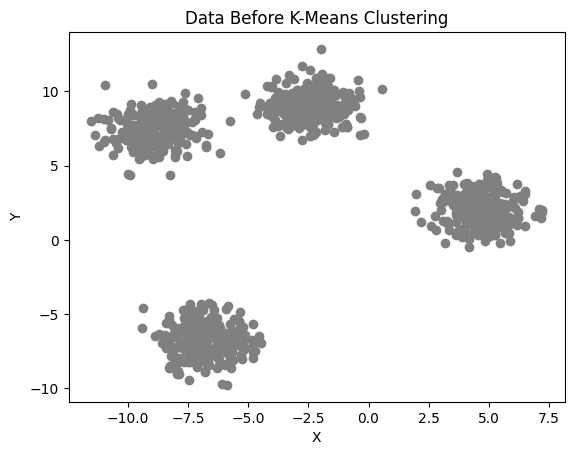

In [3]:

plt.scatter(X[:, 0], X[:, 1], color='gray')

plt.title("Data Before K-Means Clustering")
plt.xlabel("X")
plt.ylabel("Y")

plt.savefig("kmeans_data_before.png")
plt.show()


In [4]:

# Apply K-Means with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42)

labels = kmeans.fit_predict(X)

print("Cluster labels:", labels[:10])
print("Cluster centers:")
print(kmeans.cluster_centers_)


Cluster labels: [3 1 1 2 2 1 2 1 1 2]
Cluster centers:
[[-2.50173875  9.03287546]
 [-6.74543497 -6.81351756]
 [ 4.65760511  2.0269603 ]
 [-8.85662684  7.41339818]]


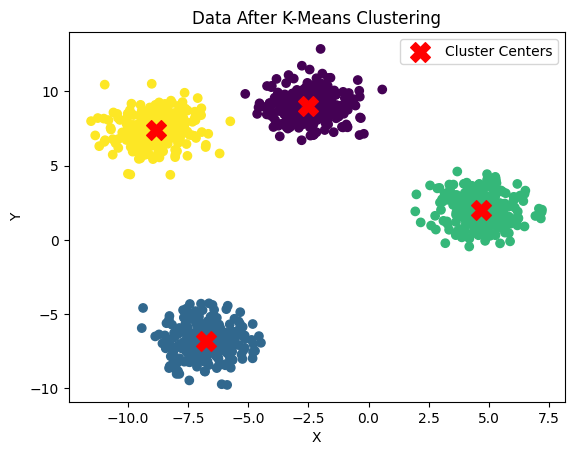

In [5]:

# Plot the clustered data
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')

# Mark the cluster centers with red X
centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    marker='X',
    s=200,
    label='Cluster Centers'
)

plt.title("Data After K-Means Clustering")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()

plt.savefig("kmeans_data_after.png")
plt.show()


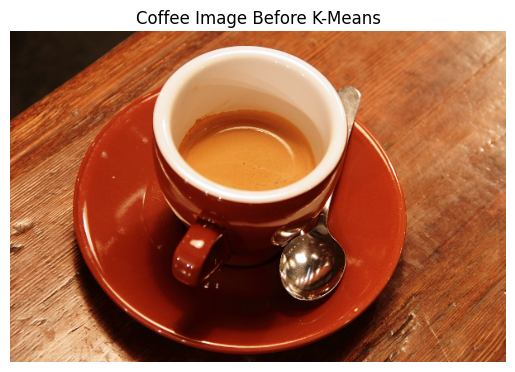

In [6]:

# Load the coffee image
coffee_image = data.coffee()

# Display the original image
plt.imshow(coffee_image)

plt.title("Coffee Image Before K-Means")
plt.axis('off')

plt.savefig("kmeans_image_before.png")
plt.show()


In [7]:

# Reshape the image into RGB pixels
pixels = coffee_image.reshape(-1, 3)

# Apply K-Means with 4 clusters
kmeans_image = KMeans(n_clusters=4, random_state=42)

# Assign each pixel to a cluster
pixel_labels = kmeans_image.fit_predict(pixels)

print("Original image shape:", coffee_image.shape)
print("Reshaped pixels:", pixels.shape)
print("Number of clusters:", kmeans_image.n_clusters)


Original image shape: (400, 600, 3)
Reshaped pixels: (240000, 3)
Number of clusters: 4


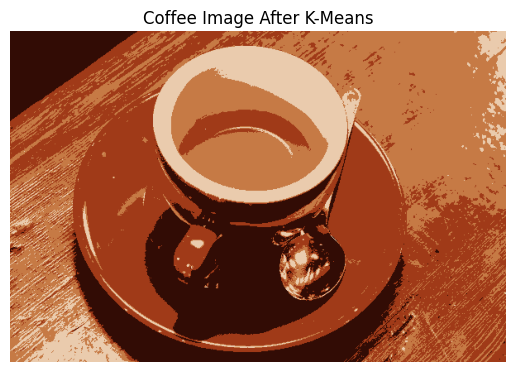

In [8]:

# Replace each pixel with its cluster center color
clustered_pixels = kmeans_image.cluster_centers_[pixel_labels]

# Reshape pixels back to the original image shape
clustered_image = clustered_pixels.reshape(coffee_image.shape)

# Convert pixel values to integers
clustered_image = np.uint8(clustered_image)

# Display the clustered image
plt.imshow(clustered_image)
plt.title("Coffee Image After K-Means")
plt.axis('off')

plt.savefig("kmeans_image_after.png")
plt.show()


# **---------------------------------------------------------**

# **Lab 2: Spectral Clustering**

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.cluster import SpectralClustering
from sklearn.cluster import spectral_clustering
from sklearn.feature_extraction import image as sk_image
from skimage import data
from skimage.transform import rescale
from skimage.filters import gaussian


In [11]:

# Generate 1000 samples in two circles
X_circles, y_circles = make_circles(
    n_samples=1000,
    factor=0.5,
    noise=0.05,
    random_state=42
)

print("Dataset shape:", X_circles.shape)
print("First 5 points:")
print(X_circles[:5])


Dataset shape: (1000, 2)
First 5 points:
[[ 0.45259239  0.16843331]
 [-0.43802652  0.11990049]
 [-0.5322243   0.18435902]
 [-0.30140181  0.40078207]
 [ 0.44560223 -0.89493556]]


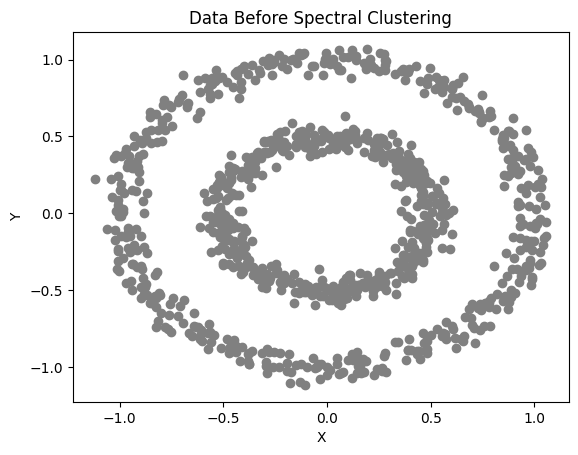

In [12]:

# Plot the dataset before Spectral Clustering
plt.scatter(X_circles[:, 0], X_circles[:, 1], color='gray')

plt.title("Data Before Spectral Clustering")
plt.xlabel("X")
plt.ylabel("Y")

plt.savefig("spectral_data_before.png")
plt.show()


In [13]:

# Apply Spectral Clustering with 2 clusters
spectral = SpectralClustering(
    n_clusters=2,
    affinity='nearest_neighbors',
    random_state=42
)

# Predict cluster labels
spectral_labels = spectral.fit_predict(X_circles)

print("First 10 cluster labels:", spectral_labels[:10])
print("Number of clusters:", len(np.unique(spectral_labels)))


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


First 10 cluster labels: [1 1 1 1 0 1 1 1 1 0]
Number of clusters: 2


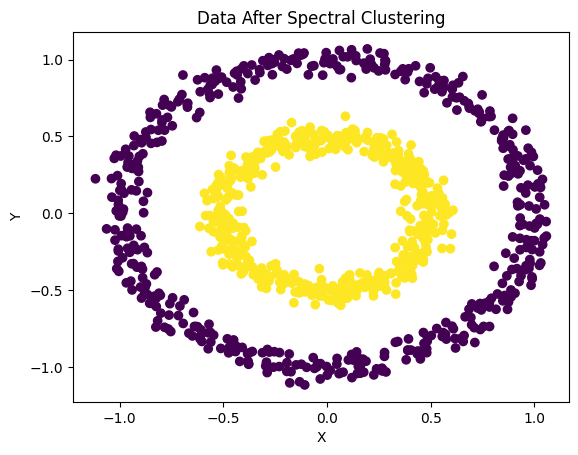

In [14]:

# Plot the data after Spectral Clustering
plt.scatter(
    X_circles[:, 0],
    X_circles[:, 1],
    c=spectral_labels,
    cmap='viridis'
)

plt.title("Data After Spectral Clustering")
plt.xlabel("X")
plt.ylabel("Y")

plt.savefig("spectral_data_after.png")
plt.show()


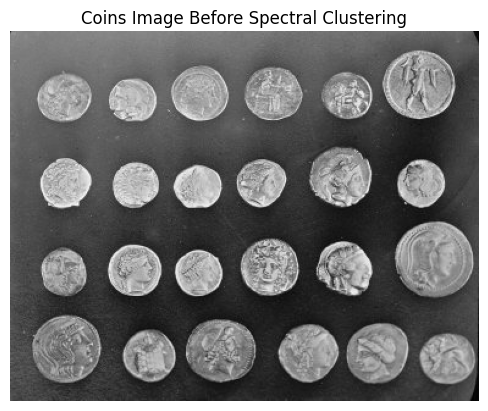

In [15]:

# Load the coins image
coins_image = data.coins()

# Display the original image
plt.imshow(coins_image, cmap='gray')

plt.title("Coins Image Before Spectral Clustering")
plt.axis('off')

plt.savefig("spectral_image_before.png")
plt.show()


In [16]:

# Smooth the image using Gaussian filter
smooth_coins = gaussian(coins_image, sigma=2)

# Resize the image to 20% of its original size
small_coins = rescale(smooth_coins, 0.2)

# Convert the image into a graph
graph = sk_image.img_to_graph(small_coins)

# Adjust graph weights
graph.data = np.exp(-10 * graph.data / graph.data.std())

print("Original image shape:", coins_image.shape)
print("Resized image shape:", small_coins.shape)
print("Graph shape:", graph.shape)


Original image shape: (303, 384)
Resized image shape: (61, 77)
Graph shape: (4697, 4697)


In [17]:

# Apply Spectral Clustering with 25 clusters
labels_coins = spectral_clustering(
    graph,
    n_clusters=25,
    assign_labels='discretize',
    random_state=42
)

# Reshape labels to match the resized image
labels_coins = labels_coins.reshape(small_coins.shape)

print("Clustered image shape:", labels_coins.shape)
print("Number of clusters:", len(np.unique(labels_coins)))


Clustered image shape: (61, 77)
Number of clusters: 25


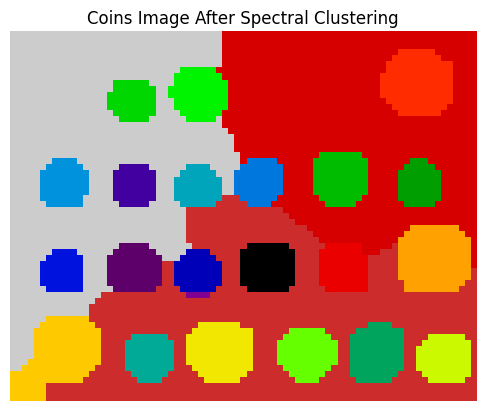

In [18]:

# Display the clustered coins image
plt.imshow(labels_coins, cmap='nipy_spectral')

plt.title("Coins Image After Spectral Clustering")
plt.axis('off')

plt.savefig("spectral_image_after.png")
plt.show()
